<div align="center">
    <b><font size="7">Group 6: Phase 3</font></b>
    <br>
    <b><font size="5">Aaron Timbang, Sergio Fernandez Donneys</font></b>
</div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

# Part 0: What Changed from Phase 2

1\. Yes, the research question was modified.

> **Phase 2:** Can a game's genre and platform be used to predict its North American sales, among VGChartz-tracked titles released through 2024 on platforms with at least 100 tracked titles?

> **Phase 3:** Can a game's genre and platform be used to predict its North American sales, among VGChartz-tracked titles released through 2020 on platforms with at least 100 tracked titles?

2\. Yes, the dataset was modified.

3\. Code to further cleaning the data set.

In [2]:
# Load Phase 2 dataset
df = pd.read_csv("../Phase 2/phase2_working.csv")

# Drop the leakage columns
leak_cols = ["Total_Sales", "JP_Sales", "PAL_Sales", "Other_Sales"]
df_p3 = df.drop(columns=leak_cols)

# Drop platforms with fewer than 100 tracked titles.
plat_counts = df_p3["Platform"].value_counts()
keep_plat = plat_counts[plat_counts >= 100].index
df_p3 = df_p3[df_p3["Platform"].isin(keep_plat)].copy()

# Save to a new csv
df_p3.to_csv("phase3_working.csv", index=False)

# Load Phase 3 dataset and check both datasets shapes.
df_p3 = pd.read_csv("phase3_working.csv")
print(f"The shape of phase2_working.csv is {df.shape}")
print(f"The shape of phase3_working.csv is {df_p3.shape}")

The shape of phase2_working.csv is (12348, 12)
The shape of phase3_working.csv is (12280, 8)


4\. The "Total_Sales" column was dropped because it is the sum of all the regional sales, so it is computed from the target. All the other regional sales ("JP_Sales", "PAL_Sales", and "Other_Sales") were dropped as well, because they are recorded after the outcome (meaning after launch, at the same time as "NA_Sales"). In addition, the 10 platforms with fewer than 100 tracked titles (68 titles in total) were dropped because several of them show have high means. It seems that the older platforms, only a few of their biggest hits were tracked.

# Part 1: Composite Portfolio

## 1A: Combine

**SLOT A1**: One Qualitative - Bar Plot of Proportions
1. What are the proportions of game titles belonging to each genre? This connects to the research question as it allows us to visualize how evenly titles are spread across genres.
2. Genre (qualitative, nominal)
3. I chose the 'bar plot of proportions' in this instance as a bar representing what percentage of each genre constitutes our dataset allows the viewer to quickly analyze the spread of titles per genre instead of a bar which says "Action has x amount of games."

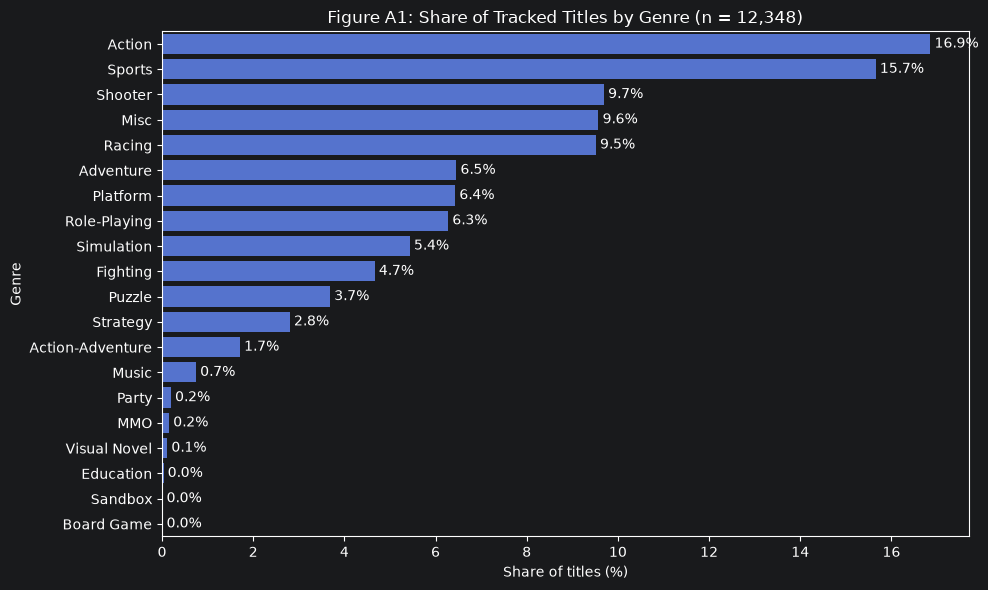

In [3]:
genre_props = df["Genre"].value_counts(normalize=True)

fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(x=genre_props.values * 100, y = genre_props.index, color = "royalblue", ax=ax)

ax.set_title("Figure A1: Share of Tracked Titles by Genre (n = 12,348)")
ax.set_xlabel("Share of titles (%)")
ax.set_ylabel("Genre")

ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()

1. Our prop bar graph shows that the Action genre holds about 17% of titles in our 12,348 rows. While the lowest considered genre of Visual Novel only has 0.1% of our dataset. We can also say that the median of titles held by each genre ranges from 6% - 9%.
2. The limit of this plot is that it does not show any correlation to our target variable which is NA_Sales, this graph only depicts proportions of titles per genre.
3. I altered perception in this case, I set horizontal bars instead so that 'genre_props.index' did not overlap.

**SLOT A2**: One Quantitative - Histogram - (NA_Sales)
1. For our 12,348 titles what is their relation to NA_Sales? This histogram relates number of titles to NA_Sales it shows how many titles have sold x amount in millions allowing us to gauge where most games land in NA_Sales.
2. NA_Sales (quantitative, continuous)
3. A histogram instead of a rug plot, since it shows actual counts of games per range which is easier to read.

count    12348.000
mean         0.271
std          0.499
min          0.010
25%          0.050
50%          0.120
75%          0.280
max          9.760
Name: NA_Sales, dtype: float64
Titles with NA_Sales <= 0: 0
Share of titles under 0.5M: 86.9 %


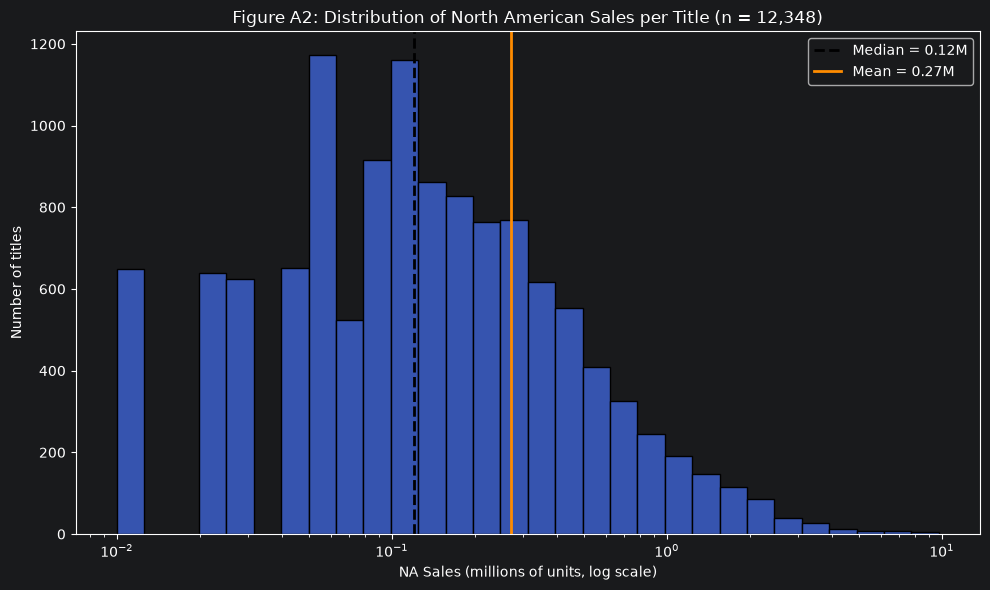

In [4]:
print(df["NA_Sales"].describe().round(3))
print("Titles with NA_Sales <= 0:", (df["NA_Sales"] <= 0).sum())
print("Share of titles under 0.5M:", round((df["NA_Sales"] < 0.5).mean() * 100, 1), "%")

med = df["NA_Sales"].median()
mean = df["NA_Sales"].mean()

fig, ax = plt.subplots(figsize=(10, 6))

sns.histplot(data=df, x="NA_Sales", log_scale=True, bins=30, color="royalblue", ax=ax)

ax.axvline(med, color="black", linestyle="--", linewidth=2, label=f"Median = {med:.2f}M")
ax.axvline(mean, color="darkorange", linestyle="-", linewidth=2, label=f"Mean = {mean:.2f}M")
ax.legend()

ax.set_title("Figure A2: Distribution of North American Sales per Title (n = 12,348)")
ax.set_xlabel("NA Sales (millions of units, log scale)")
ax.set_ylabel("Number of titles")

plt.tight_layout()
plt.show()

1. Our distribution shows that a majority of our games range from 100k sales up to 500k NA_Sales with the median being 0.12M and then mean being 0.27M. The graph is skewed right due to blockbuster games such as GTA and Call of Duty inflating sales up to 10M.
2. Ultimately, this graph does not show any reasoning as to what or why games sell well. It does not factor in our genre and platform columns it only represents how many titles have sold for x amount.
3. The principle which I checked and changed was scale. Following the given example I actually used a log x-axis as well since the prior method clustered many of the bars to the left (anything below 0.5M) using a log x-axis gave us a better spread to represent NA_Sales.

**SLOT A3**: One Quantitative across a qualitative - Box Plot
1. How do different genres relate to their NA_Sales? This is a direct connection our research question as we are able to identify quartiles, ranges, and outliers per each genre in relation to their sales.
2. NA_Sales (quantitative, continuous), Genre (qualitative, nominal)
3. A box plot was the clear winner in this scenario, we are able to compare 13 genres side by side with visual representation of each median and outlier values instead of a violin plot where data may be more difficult to interpret.

Rows before filter: 12348
Rows after filter: 12193
Genres kept: 13 of 20
Genre
Sports              0.15
Shooter             0.15
Action-Adventure    0.14
Fighting            0.14
Action              0.13
Platform            0.13
Misc                0.12
Simulation          0.11
Adventure           0.10
Racing              0.10
Role-Playing        0.10
Puzzle              0.07
Strategy            0.06
Name: NA_Sales, dtype: float64


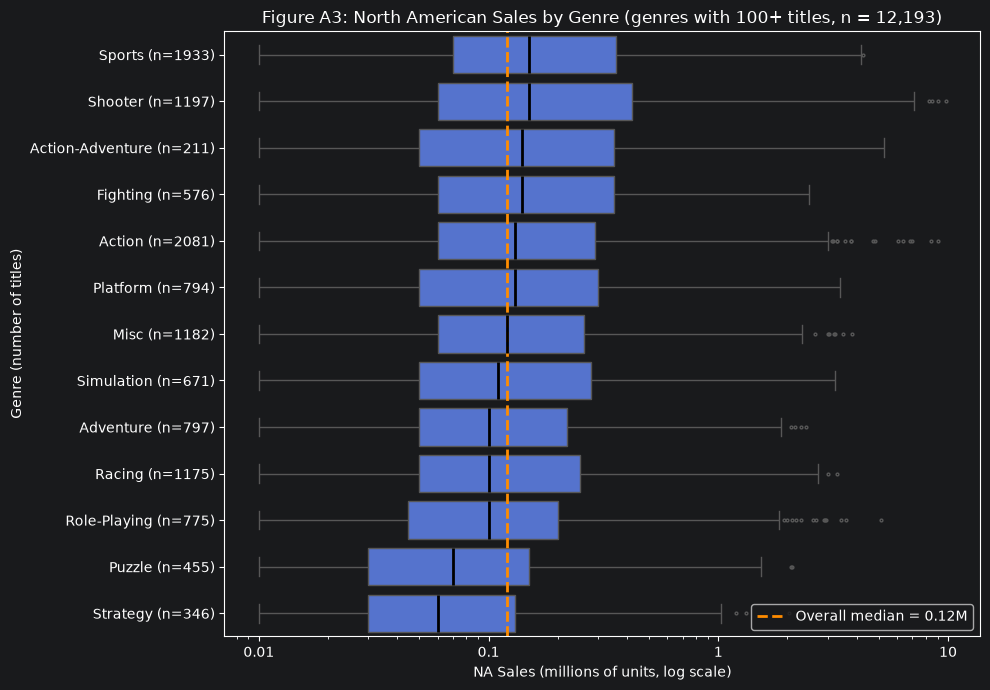

In [5]:
genre_counts = df["Genre"].value_counts()
big_genres = genre_counts[genre_counts >= 100].index
df_a3 = df[df["Genre"].isin(big_genres)]

print("Rows before filter:", len(df))
print("Rows after filter:", len(df_a3))
print("Genres kept:", len(big_genres), "of", genre_counts.size)

genre_medians = df_a3.groupby("Genre")["NA_Sales"].median().sort_values(ascending=False)
print(genre_medians.round(2))

order = genre_medians.index
labels = [f"{g} (n={genre_counts[g]})" for g in order]
overall_med = df_a3["NA_Sales"].median()

fig, ax = plt.subplots(figsize=(10, 7))

sns.boxplot(data=df_a3, x="NA_Sales", y="Genre", order=order, log_scale=True,
            color="royalblue", fliersize=2,
            medianprops={"color": "black", "linewidth": 2}, ax=ax)

ax.set_yticks(range(len(order)))
ax.set_yticklabels(labels)

ax.set_xticks([0.01, 0.1, 1, 10])
ax.set_xticklabels(["0.01", "0.1", "1", "10"])

ax.axvline(overall_med, color="darkorange", linestyle="--", linewidth=2,
           label=f"Overall median = {overall_med:.2f}M")
ax.legend(loc="lower right")

ax.set_title("Figure A3: North American Sales by Genre (genres with 100+ titles, n = "
             f"{len(df_a3):,})")
ax.set_xlabel("NA Sales (millions of units, log scale)")
ax.set_ylabel("Genre (number of titles)")

plt.tight_layout()
plt.show()

1. To support our research question I filtered genres which held at least 100 titles. The most obvious facet that this plot shows is that Action and Role-Playing games have the most outlier titles driving their upper whiskers further. Furthermore, we can see that the overall median is 0.12M across all genres.
2. This bar plot is limited by only one comparative variable to our target variable, we have left out platform in relation to NA_Sales.
3. I checked the conditioning principle this time around, I explicitly added the median line for viewers to easily identify the which genres perform better overall.

**SLOT A4**: Two quantitative - Scatter plot w/ alpha (Critic_Score vs. NA_Sales)
1. Do titles with higher critic scores tend to sell more in North America? Critic_Score is not one of our two named predictors, but if it relates strongly to NA_Sales, it is a candidate feature that could explain sales differences that genre and platform alone miss.
2. Critic_Score (quantitative, continuous, on a 1–10 scale), NA_Sales (quantitative, continuous).
3. A scatter plot with alpha instead of a hex plot, because thousands of points overlap and transparency reveals where they bunch up while still showing every individual title, including the few blockbusters that a hex plot would blend into shaded cells.

Rows before filter: 12348
Rows after filter: 3674
Share kept: 29.8 %
count    3674.00
mean        7.08
std         1.43
min         1.00
25%         6.30
50%         7.30
75%         8.10
max        10.00
Name: Critic_Score, dtype: float64
Spearman correlation: 0.368


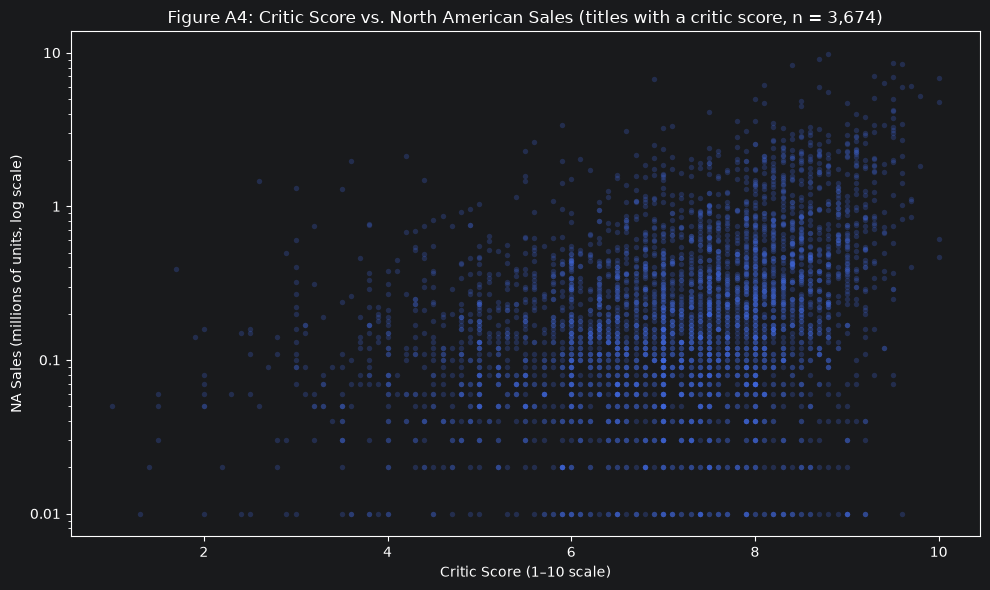

In [6]:
df_a4 = df.dropna(subset=["Critic_Score"])

print("Rows before filter:", len(df))
print("Rows after filter:", len(df_a4))
print("Share kept:", round(len(df_a4) / len(df) * 100, 1), "%")
print(df_a4["Critic_Score"].describe().round(2))

spearman = df_a4["Critic_Score"].corr(df_a4["NA_Sales"], method="spearman")
print("Spearman correlation:", round(spearman, 3))

fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(data=df_a4, x="Critic_Score", y="NA_Sales",
                alpha=0.25, s=15, color="royalblue", linewidth=0, ax=ax)

ax.set_yscale("log")
ax.set_yticks([0.01, 0.1, 1, 10])
ax.set_yticklabels(["0.01", "0.1", "1", "10"])

ax.set_title(f"Figure A4: Critic Score vs. North American Sales (titles with a critic score, n = {len(df_a4):,})")
ax.set_xlabel("Critic Score (1–10 scale)")
ax.set_ylabel("NA Sales (millions of units, log scale)")

plt.tight_layout()
plt.show()

1. This is not my favorite representation of our dataset but the use of two quantitative variables was required. In this instance we can see that titles with a higher critic score are denoted with increasing and darker plots. The range from 6-10 is where the majority of our dots reside indicating that the increase in critic score has a direct relation to an increase in NA_Sales.
2. This plot is limited by rows which actually have a critic score so those without one or a NULL value are not represented in this plot.
3. Perception is the principle check in this plot, using the alpha filter gives a better depiction of the actual data instead of overlapping points at full opacity; since our eyes are trained to identify the largest entity changing the opacity presents more factual data with darker points illustrating where the real numbers reside.

## Figure B1: Among platforms with at least 100 tracked titles, how evenly are titles distributed?
If the data is concentrated on a few platforms, predictions for smaller platforms will rest on a lot less evidence.

> **Variables**: Platform (Qualitative Nominal)

A horizontal bar chart counts, sorted from most to fewest titles. Bars compare lengths, which the eye can judge accurately. I chose counts over proportions because the question is about how much evidence each platform contributes, and raw titles show that sample size directly while proportions would hide it.

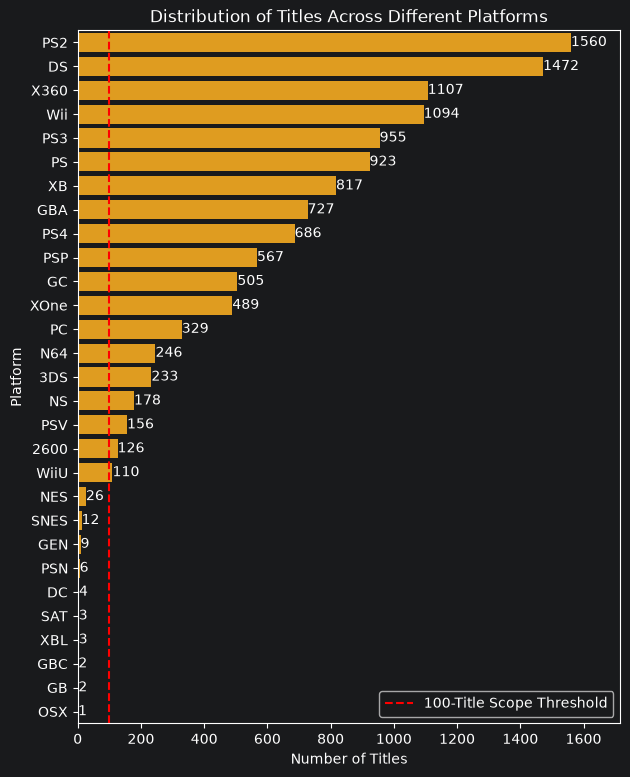

In [7]:
platform_counts = df["Platform"].value_counts()
countplot_order = platform_counts.index

plt.figure(figsize=(7,9))
ax = sns.countplot(df, y="Platform", color="orange", order=countplot_order)
bars= ax.containers[0]
ax.bar_label(bars)
plt.axvline(x=100, color="red", label="100-Title Scope Threshold", linestyle="--")
plt.xlabel("Number of Titles")
plt.xlim(0, platform_counts.max() * 1.1)
plt.ylabel("Platform")
plt.title("Distribution of Titles Across Different Platforms")
plt.legend()
plt.show()

**What it shows:** The PS2 has the most titles, with 1,560, while the Wii U has the fewest of the platforms within our research question's scope, with just 110. Ten platforms fall below the 100-title threshold that our research question requires. The titles are not spread evenly at all, with the number of titles dropping significantly after the top 2.

**What it does not show:** This plot does not necessarily show that a platform with 1,560 tracked titles sells more games per title than a platform with only 110 games.

**Principle check:** Context. I added a reference line at 100 titles so readers can immediately see which platforms meet our scope.

## Figure B2: How are critic scores distributed among the in-scope titles, and how many titles have a score at all?
This will determine whether Critic_Score could serve as a control variable alongside genre and platform, or whether it is too incomplete to use.

> **Variables:** Critic_Score (Quantitative Continuous)

A histogram instead of a KDE, because I want to see spikes, gaps, or values stacked at round numbers that a smoothed density curve would hide.

In [8]:
total = len(df)
scored = df["Critic_Score"].notna().sum()
print(f"Titles with a critic score: {scored} of {total} -> {scored / total:.1%}\n")

print(df["Critic_Score"].describe())

min_score = df["Critic_Score"].min()
print(f"\nTitles at a minimum score of {min_score}: {(df['Critic_Score'] == min_score).sum()}")

Titles with a critic score: 3674 of 12348 -> 29.8%

count    3674.000000
mean        7.081410
std         1.432583
min         1.000000
25%         6.300000
50%         7.300000
75%         8.100000
max        10.000000
Name: Critic_Score, dtype: float64

Titles at a minimum score of 1.0: 1


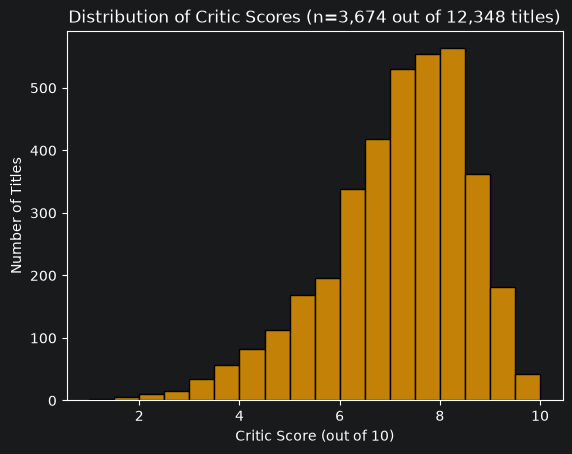

In [9]:
sns.histplot(df["Critic_Score"], color="orange", binwidth=0.5)
plt.xlabel("Critic Score (out of 10)")
plt.ylabel("Number of Titles")
plt.title("Distribution of Critic Scores (n=3,674 out of 12,348 titles)")
plt.show()

**What it shows:** Only 3,674 out of 12,348 titles (29.8%) have a critic score. On a scale out of 10, scores have a median and mean of 7.3 and 7.08 respectively, with the middle 50% falling between 6.3 and 8.1. The mean sitting below the median reflects a left skew, with a peak in the 8.0-8.5 bin and a tail going to the left. I do not think critic score can be used as a control variable since only 29.8% of the titles have scores.

**What it does not show:** This plot does not show if there is a correlation between higher scores and higher sales.

**Principle check:** Scale. I compared bin widths of 0.25, 0.5 and 1.0 and kept 0.5. Because scores are recorded to one decimal place, 0.25 bins held an uneven number of score values and produced false spikes and gaps, while 1.0 merged the peak into a few wide blocks; at 0.5 every bin holds the same number of possible scores.

## Figure B3: Among platforms with at least 100 tracked titles, does North America sales per title differ by platform enough that it could help predict NA_Sales?
This tests half of our research question directly.

> **Variables:** NA_Sales (Quantitative Continuous) across Platform (Qualitative Nominal)

Horizontal box plots sorted by median, instead of violins, because with this many platforms the violin shapes would crowd each other, while boxes still allow a clean comparison of medians and spread.

**Filtered view for B3:** Because Plot B1 shows that several platforms fall outside the scope of our research question, B3 uses only platforms with at least 100 titles, so that no box is based on too few games to compare fairly.

In [10]:
in_scope = platform_counts[platform_counts >= 100].index

b3_df = df[df["Platform"].isin(in_scope)]

print(f"Rows before: {len(df)}, after: {len(b3_df)}. Total number of rows removed: {len(df) - len(b3_df)}")
print(f"Platforms before: {df['Platform'].nunique()}, after: {b3_df['Platform'].nunique()}")


Rows before: 12348, after: 12280. Total number of rows removed: 68
Platforms before: 29, after: 19


In [11]:
zero_sales = (b3_df["NA_Sales"] == 0).sum()
missing_sales = b3_df["NA_Sales"].isna().sum()
min_sales = b3_df["NA_Sales"].min()

print(f"Titles with zero NA sales: {zero_sales}")
print(f"Titles with missing NA sales: {missing_sales}")
print(f"Lowest NA sales value: {min_sales}")

Titles with zero NA sales: 0
Titles with missing NA sales: 0
Lowest NA sales value: 0.01


In [12]:
sales_median = b3_df["NA_Sales"].groupby(b3_df["Platform"]).median().sort_values(ascending=False)
boxplot_order = sales_median.index
print(f"Median sales value in millions of units.\n{sales_median}")

Median sales value in millions of units.
Platform
2600    0.420
X360    0.190
N64     0.180
PS3     0.180
Wii     0.140
PS2     0.130
WiiU    0.125
PS      0.120
3DS     0.100
DS      0.100
GBA     0.100
XB      0.100
PSP     0.100
GC      0.100
XOne    0.090
PS4     0.080
NS      0.050
PSV     0.045
PC      0.040
Name: NA_Sales, dtype: float64


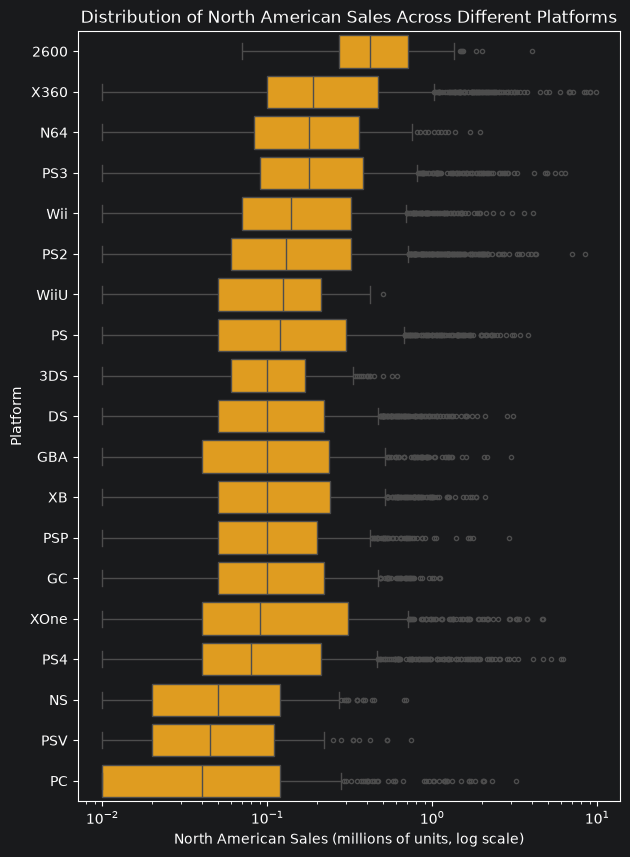

In [13]:
plt.figure(figsize=(7,10))
sns.boxplot(b3_df, x="NA_Sales", y="Platform", orient="h", color="orange", order=boxplot_order, fliersize=3)
plt.xscale("log")
plt.xlabel("North American Sales (millions of units, log scale)")
plt.ylabel("Platform")
plt.title("Distribution of North American Sales Across Different Platforms")
plt.show()

**What it shows:** Using only the 19 in-scope platforms, median North American sales range from 0.42 million for the 2600 to 0.04 million for PC, so the 2600's median is about 10 times higher. Without the 2600, the range goes from 0.04 million (PC) to 0.19 million (X360), which is only about 4.75 times higher. This means the 2600 alone accounts for most of the gap, and the other 18 platforms are much closer together. This answers our question: North American sales per title do not differ much between platforms.

**What it does not show:** The number of titles behind each box is not visible. A box built from 110 titles (Wii U) looks just as solid as one built from 1,560 (PS2).

**Principle check:** Scale. I switched to a log x-axis because on the linear axis the boxes were flattened against zero; the log axis shows each platform's spread.

## Figure B4: For titles released through 2024, has North America sales per title shifted over time?
If it has, release era could be confounding the platform differences in Figure B3, since each platform belongs to a specific era.

> **Variables:** Release year (Quantitative Discrete) and NA_Sales (Quantitative Continuous)

A hex plot instead of a scatter plot, because with over 12,000 titles the scatter turned into a solid block even with jitter and transparency, hiding where titles concentrate. Coloring each hexagon by its title count shows that density directly, and a log y-axis keeps the many low-selling titles from being crushed by a few blockbusters.

In [14]:
release_year = pd.to_datetime(df["Release_Date"], format="%m/%d/%Y").dt.year

titles_year = release_year.value_counts().sort_index()
median_year = df["NA_Sales"].groupby(release_year).median()

titles_median = pd.DataFrame({
    "Titles": titles_year,
    "Median NA Sales (millions of units)": median_year
}).rename_axis("Release Year")

print("Titles and median North American sales per release year:\n", titles_median)

Titles and median North American sales per release year:
               Titles  Median NA Sales (millions of units)
Release Year                                             
1977.0             3                                0.910
1978.0             7                                0.350
1979.0             1                                0.290
1980.0             5                                0.440
1981.0             6                                0.725
1982.0            44                                0.435
1983.0            37                                0.500
1984.0             9                                0.430
1985.0             2                                0.420
1986.0             4                                0.370
1987.0             5                                0.450
1988.0             8                                0.370
1989.0             5                                0.220
1990.0             6                                0.290
1991.0        

Titles plotted: 12339 of 12348
Titles missing a year or NA sales: 9


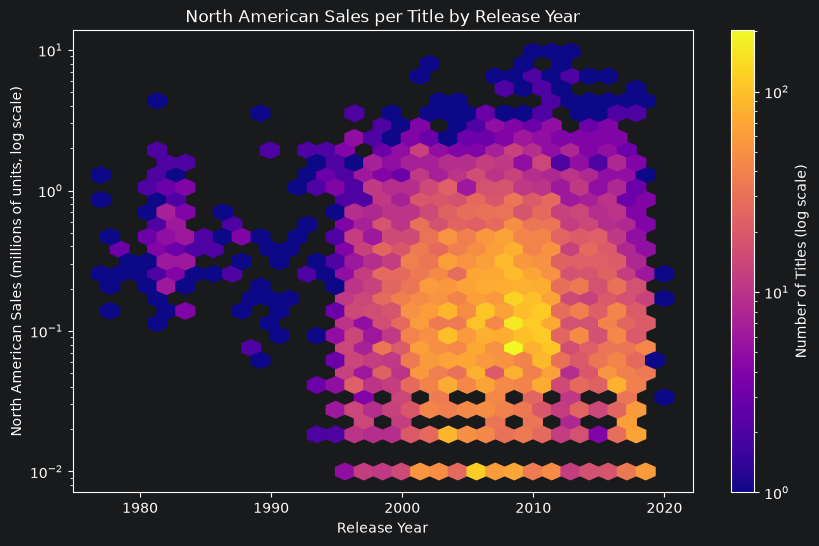

In [15]:
has_both =  release_year.notna() & df["NA_Sales"].notna()
print(f"Titles plotted: {has_both.sum()} of {len(df)}\nTitles missing a year or NA sales: {len(df) - has_both.sum()}")

plt.figure(figsize=(10,6))
hb = plt.hexbin(release_year[has_both], df["NA_Sales"][has_both], gridsize=30, yscale="log", bins="log", cmap="plasma", mincnt=1)

cb = plt.colorbar(hb)
cb.set_label("Number of Titles (log scale)")
plt.xlabel("Release Year")
plt.ylabel("North American Sales (millions of units, log scale)")
plt.title("North American Sales per Title by Release Year")
plt.show()

**What it shows:** Before 1995, only a handful of games were tracked (1 to 44 titles), but their medians were extremely high, ranging from about 0.21 to 1.02 million; in my opinion this is selection bias, since years later only the biggest hits were recorded. From 1995 to 2015, the number of tracked titles varies a lot (from 51 in 1995 to 1,070 in 2009), but the median stays about the same, between 0.09 and 0.19 million. After 2015 the median decreases (0.08 in 2016, 0.06 in 2017, and 0.05 in 2018), there are no tracked titles for 2019, and only 4 titles for 2020.

**What it does not show:** The graph does not show which platform each title belongs to, so it cannot tell whether the platform differences in B3 are really era differences.

**Principle check:** Perception. I switched from a jittered scatter plot to a hex plot, because even with jitter and transparency the scatter plot hid where the concentration really happened.


| Figure | Member | Slot | Variables | Question it answers | Principle checked |
|--------|--------|------|-----------|---------------------|-------------------|
| A1 | Aaron | 1 | Genre | What share of titles does each genre hold? | Perception |
| A2 | Aaron | 2 | NA_Sales | How are NA sales per title distributed? | Scale |
| A3 | Aaron | 3 | NA_Sales across Gnere | Do NA sales differ by genre? | Conditioning |
| A4 | Aaron | 4 | Critic_Score vs. NA_Sales | Do higher critic score | Perception |
| B1 | Sergio | 1 | Platform (title count) | How evenly are titles spread across platforms? | Context |
| B2 | Sergio | 2 | Critic_Score | How are critic scores distributed, and how many titles have one? | Scale |
| B3 | Sergio | 3 | Platform across NA_Sales | Do NA sales per title differ by platform? | Scale |
| B4 | Sergio | 4 | Release year across NA_Sales | Have NA sales per title shifted over the years? | Perception |

Figures A4 and B2 do not contradict each other, but they pull in different directions. A4 suggests a moderate positive relationship between critic scores and North American sales (Spearman correlation of 0.37), while B2 shows that only 29.8% of titles have critic scores at all. We trust B2, and in our opinion critic score does not belong in the model, because too few titles have a score for that information to be trustworthy. Figures A1 and B1 show a similar pattern: in both, two categories lead (Action and Sports hold 32.6% of the titles, and PS2 and DS lead the platforms), followed by a long tail of categories with very few titles. Comparing A3 and B3, median North American sales are more evenly distributed across genres (0.06 to 0.15 million) than across platforms (0.04 to 0.19 million, or up to 0.42 million including the 2600). Therefore, this comparion suggest that platform is the better predictor for our research question.

## 1B: Upgrade the Two Weakest

### A2 fails scale: because North American sales are recorded in 0.1 increments, the log-spaced bins catch an uneven number of possible values, creating gaps that suggest no games sold in those ranges and spikes that reflect how many values each bin happened to catch rather than real differences in sales.

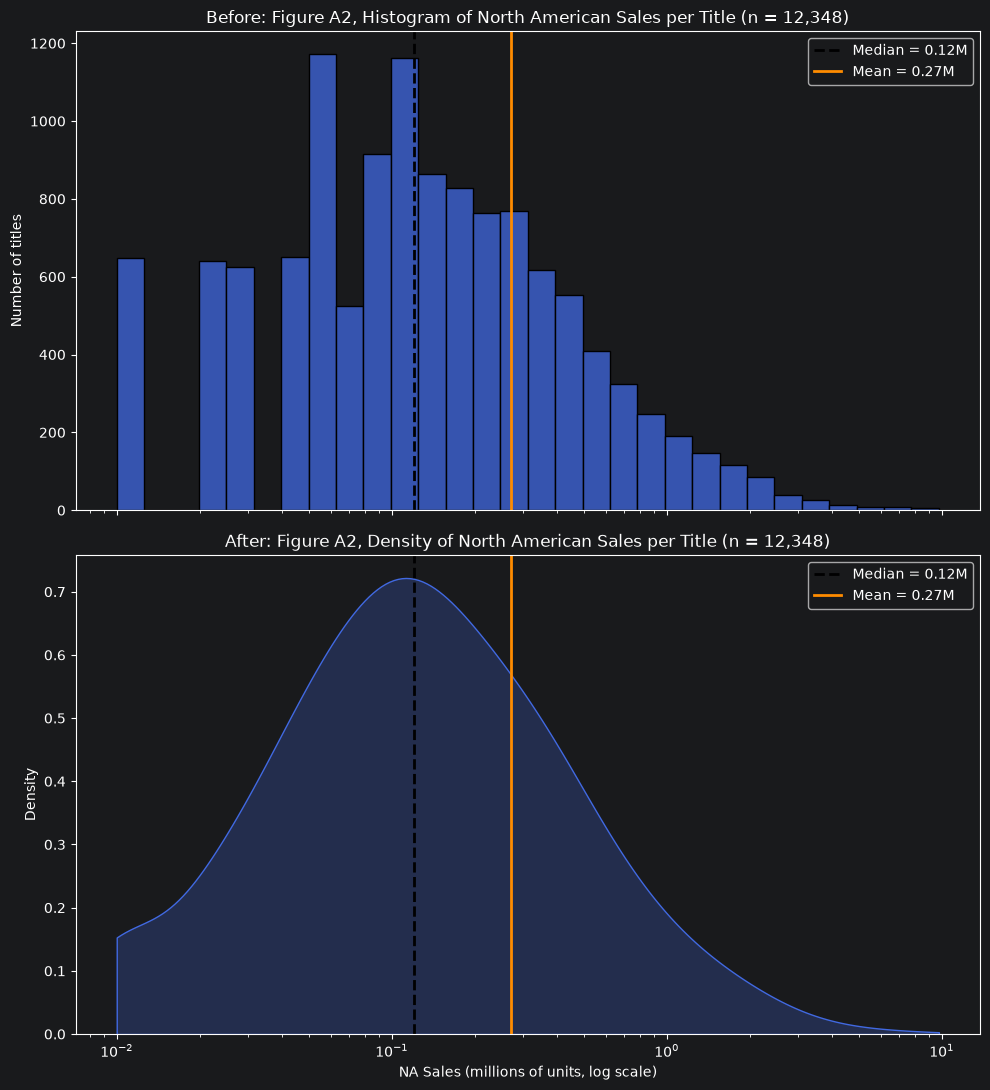

In [27]:
fig, (ax_before, ax_after) = plt.subplots(2, 1, figsize=(10, 11), sharex=True)

# Before: original A2 histogram
sns.histplot(data=df, x="NA_Sales", log_scale=True, bins=30, color="royalblue", ax=ax_before)

ax_before.axvline(med, color="black", linestyle="--", linewidth=2, label=f"Median = {med:.2f}M")
ax_before.axvline(mean, color="darkorange", linestyle="-", linewidth=2, label=f"Mean = {mean:.2f}M")
ax_before.legend()

ax_before.set_title("Before: Figure A2, Histogram of North American Sales per Title (n = 12,348)")
ax_before.set_ylabel("Number of titles")

# After: KDE on the same log axis
sns.kdeplot(data=df, x="NA_Sales", log_scale=True, bw_adjust=2, cut=0, fill=True,
            color="royalblue", ax=ax_after)

ax_after.axvline(med, color="black", linestyle="--", linewidth=2, label=f"Median = {med:.2f}M")
ax_after.axvline(mean, color="darkorange", linestyle="-", linewidth=2, label=f"Mean = {mean:.2f}M")
ax_after.legend()

ax_after.set_title("After: Figure A2, Density of North American Sales per Title (n = 12,348)")
ax_after.set_xlabel("NA Sales (millions of units, log scale)")
ax_after.set_ylabel("Density")

plt.tight_layout()
plt.show()

# Part 2: Lie Detector
## 2A: The Swap

### Aaron

### Sergio

## 2B: Both Plots, Fixed

## MA: MISLEADING ON PURPOSE

### SHOOTER GAMES SELL 3X MORE THAN SPORTS GAMES

Genre
Shooter             0.441
Sports              0.314
Action-Adventure    0.308
Fighting            0.302
Action              0.283
Misc                0.250
Platform            0.237
Racing              0.230
Simulation          0.228
Role-Playing        0.222
Adventure           0.197
Puzzle              0.141
Strategy            0.136
Name: NA_Sales, dtype: float64
Actual ratio, Shooter vs Strategy: 3.2x
Area ratio when bubbles scale by radius: 10.5x


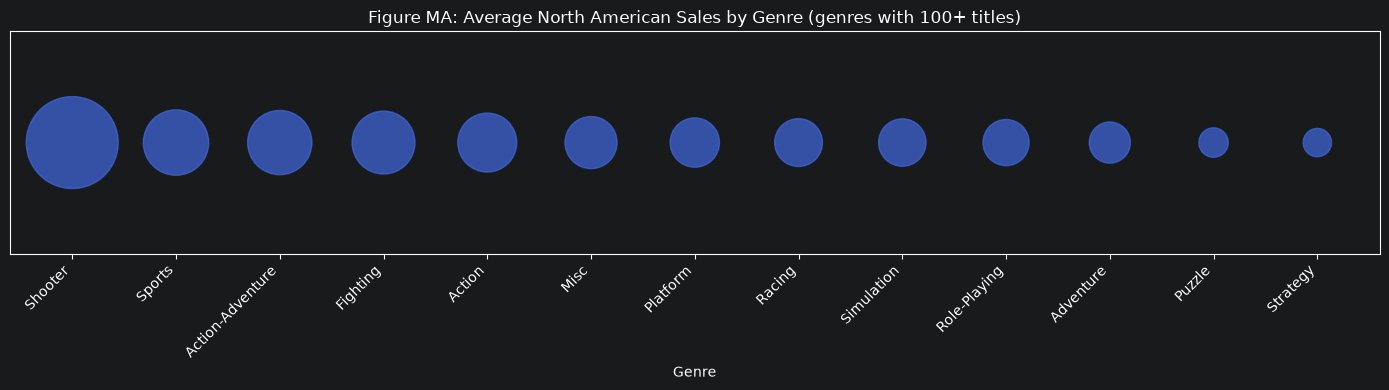

In [16]:
genre_means = df_a3.groupby("Genre")["NA_Sales"].mean().sort_values(ascending=False)
print(genre_means.round(3))

ratio = genre_means.iloc[0] / genre_means.iloc[-1]
print(f"Actual ratio, {genre_means.index[0]} vs {genre_means.index[-1]}: {ratio:.1f}x")
print(f"Area ratio when bubbles scale by radius: {ratio ** 2:.1f}x")

x_pos = range(len(genre_means))

fig, ax = plt.subplots(figsize=(14, 4))

ax.scatter(x_pos, [0] * len(genre_means),
           s=(genre_means.values * 150) ** 2,
           color="royalblue", alpha=0.7)

ax.set_xticks(x_pos)
ax.set_xticklabels(genre_means.index, rotation=45, ha="right")
ax.set_yticks([])
ax.set_ylim(-1, 1)

ax.set_title("Figure MA: Average North American Sales by Genre (genres with 100+ titles)")
ax.set_xlabel("Genre")

plt.tight_layout()
plt.show()

## The Honest Plot

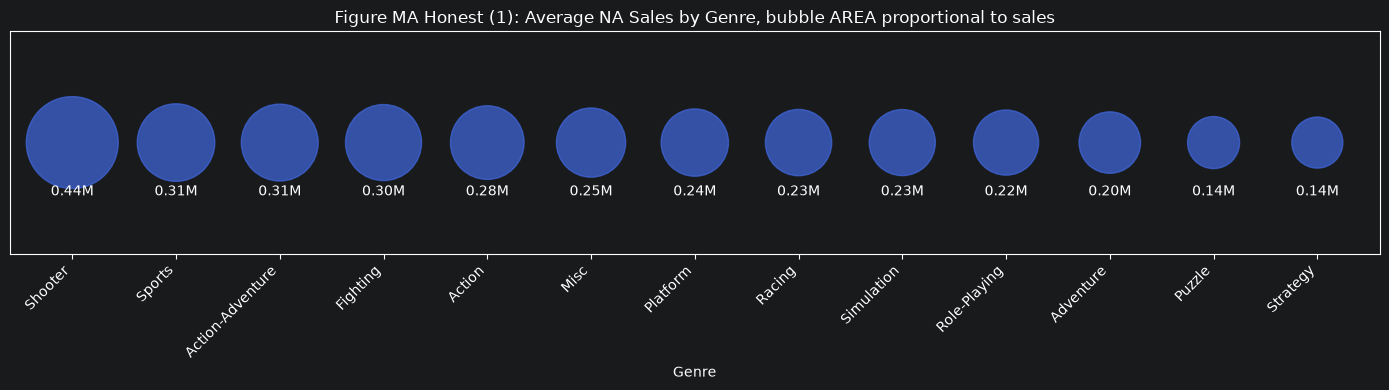

In [17]:
max_area = (genre_means.max() * 150) ** 2
honest_s = genre_means.values / genre_means.max() * max_area

fig, ax = plt.subplots(figsize=(14, 4))

ax.scatter(x_pos, [0] * len(genre_means), s=honest_s, color="royalblue", alpha=0.7)

for x, val in zip(x_pos, genre_means.values):
    ax.annotate(f"{val:.2f}M", (x, 0), xytext=(0, -38), textcoords="offset points", ha="center")

ax.set_xticks(x_pos)
ax.set_xticklabels(genre_means.index, rotation=45, ha="right")
ax.set_yticks([])
ax.set_ylim(-1, 1)

ax.set_title("Figure MA Honest (1): Average NA Sales by Genre, bubble AREA proportional to sales")
ax.set_xlabel("Genre")

plt.tight_layout()
plt.show()

## How the Tricks Works
1. Figure 1 breaks the perception principle.
2. The damage comes from `s=(genre_means.values * 150) ** 2`
3. A reader's eye falls for it because we judge objects or in this case circles by how much space they cover not by their width. Like the perception example in class we were not able to gauge how many smaller circles were able to fit into a larger one as we based it on area instead of length.
4. The honest plot shows makes 's' a straight fraction of the biggest bubble without the squaring function; half the sales means half the area. Moreover, we set values underneath each bubble to indicate the actual growth from each genre/bubble.


## MB: MISLEADING ON PURPOSE

### Title for Title, Sega Genesis Outsells Xbox 360

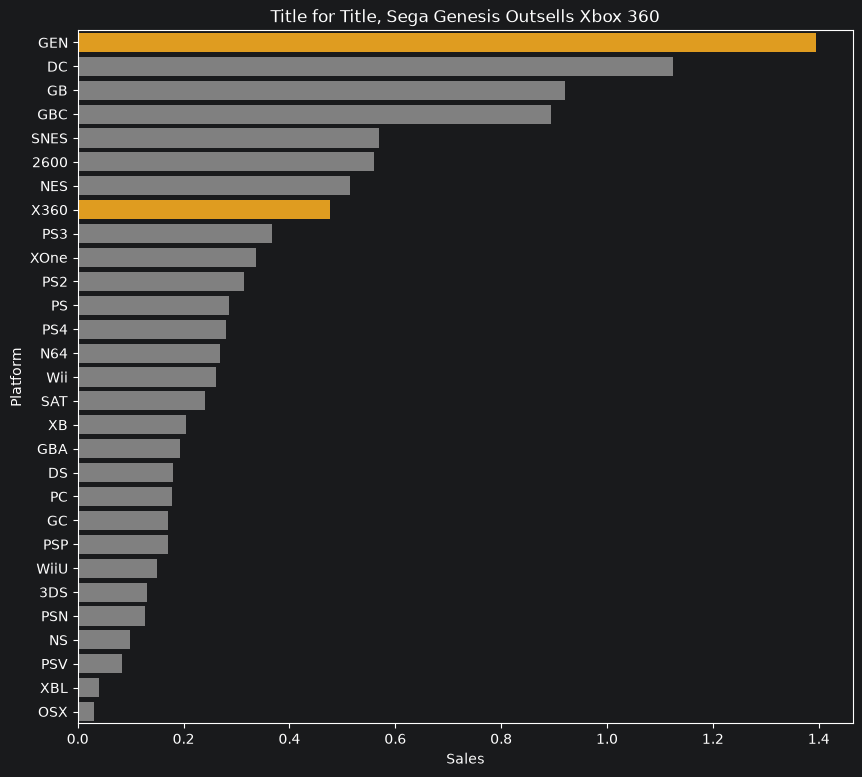

In [18]:
platform_stats = df.groupby("Platform")["NA_Sales"].agg(["mean", "count"]).sort_values("mean", ascending=False)
# Color palette
colors = {i: ("orange" if i in ["GEN", "X360"] else "gray" ) for i in platform_stats.index}

plt.figure(figsize=(10,9))
sns.barplot(x=platform_stats["mean"], y=platform_stats.index, hue=platform_stats.index, palette=colors, legend=False, errorbar=None)
plt.xlabel("Sales")
plt.ylabel("Platform")
plt.title("Title for Title, Sega Genesis Outsells Xbox 360")
plt.show()

## The Honest Plot

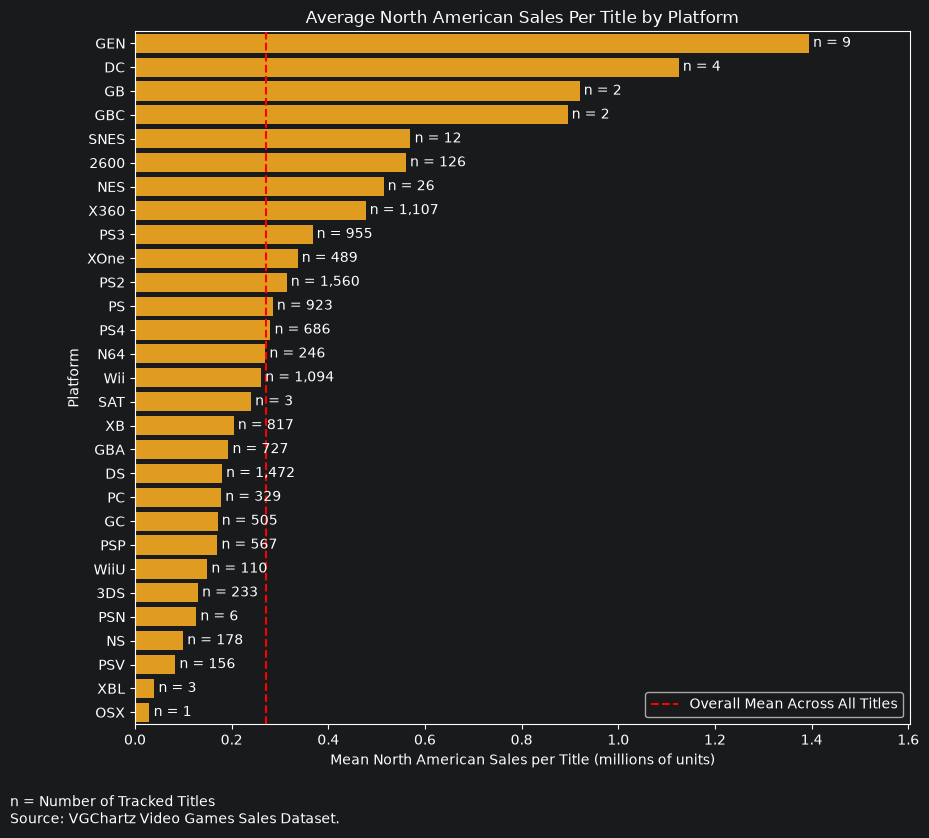

In [19]:
sales_mean = df["NA_Sales"].mean()

plt.figure(figsize=(10,9))
ax = sns.barplot(x=platform_stats["mean"], y=platform_stats.index, color="orange", errorbar=None)

labels = [f"n = {n:,}" for n in platform_stats["count"]]
ax.bar_label(ax.containers[0], labels=labels, padding=3)

plt.axvline(x=sales_mean, color="red", label="Overall Mean Across All Titles", linestyle="--", zorder=1)
plt.xlim(0, platform_stats["mean"].max() * 1.15)
plt.xlabel("Mean North American Sales per Title (millions of units)")
plt.ylabel("Platform")
plt.title("Average North American Sales Per Title by Platform")
plt.figtext(x=0, y=0, s="n = Number of Tracked Titles\nSource: VGChartz Video Games Sales Dataset.")
plt.legend()
plt.show()

## How the Trick Works

The principle I broke is context. In the misleading plot, the title was leading (`plt.title("Title for Title, Sega Genesis Outsells Xbox 360")`), the x-axis label was left vague on purpose (`plt.xlabel("Sales")`), and the bar labels showing each platform's sample size were left out, while an orange accent on GEN and X360 pointed the reader straight at that comparison. The reader immediately sees that the Sega Genesis has the biggest bar, and the leading title and vague "Sales" label lead them to conclude the headline is correct. The honest plot fixes the title and x-axis label to describe what is actually being measured, adds the sample size to each bar so the reader knows how many titles are behind each average, and uses one color for all platforms. The headline does survive in a narrow sense, since the Sega Genesis really does have a higher sales average, but it falls apart once you see the difference in titles tracked (9 for the Genesis versus 1,107 for the Xbox 360): older consoles have far fewer titles in the dataset, and the ones tracked appear to be their biggest hits, which pushes the average up.



## 2C: The Checklist

# Part 3: Hero Figure

# Part 4: The Model Case

# Part 5: Honest Data Story

## AI Usage
Claude to correct syntax in the plotting of the before and after weakest plot in the two panel stack format in part 1B.